In [ ]:
import glob
import urllib.request
import zipfile

DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/fra-eng.zip"
ZIP_PATH = "fra-eng.zip"
EXTRACT_DIR = "data_raw"

urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH) as zip_file:
    zip_file.extractall(EXTRACT_DIR)

text_file = glob.glob(f"{EXTRACT_DIR}/**/fra.txt", recursive=True)[0]

print("Dataset file:", text_file)

Dataset file: data_raw/fra.txt


In [ ]:
import csv
import pandas as pd

pairs = pd.read_csv(
    text_file,
    sep="\t",
    header=None,
    usecols=[0, 1],
    names=["en", "fr"],
    quoting=csv.QUOTE_NONE,
    encoding="utf-8"
)

print("Number of pairs:", len(pairs))
pairs.sample(5, random_state=42)

Number of pairs: 167130


,en,fr
59241,I think it's fascinating.,Je pense que c'est fascinant.
135841,Why don't we talk about something else?,Pourquoi ne parlons-nous pas d'autre chose ?
113994,I don't really know what you mean.,Je ne sais pas vraiment ce que tu veux dire.
138328,Those prisoners were set free yesterday.,Ces prisonnières ont été libérées hier.
31886,You're a funny girl.,T'es une drôle de fille.


In [ ]:
rows_before = len(pairs)

pairs = pairs.dropna(subset=["en", "fr"]).copy()

pairs["en"] = pairs["en"].str.strip()
pairs["fr"] = pairs["fr"].str.strip()

pairs["en_words"] = pairs["en"].str.split().str.len()

pairs = pairs[(pairs["en"] != "") & (pairs["fr"] != "")]
pairs = pairs.drop_duplicates(subset=["en", "fr"])
pairs = pairs[pairs["en_words"] <= 15]

pairs = pairs.reset_index(drop=True)

print("Rows before cleaning:", rows_before)
print("Rows after cleaning:", len(pairs))
print("Rows removed:", rows_before - len(pairs))
print("Unique English sentences:", pairs["en"].nunique())
print("Longest English sentence:", pairs["en_words"].max(), "words")

Rows before cleaning: 167130
Rows after cleaning: 166340
Rows removed: 790
Unique English sentences: 116198
Longest English sentence: 15 words


In [ ]:
from sklearn.model_selection import train_test_split

unique_en = pairs["en"].drop_duplicates()

train_en, test_en = train_test_split(
    unique_en,
    test_size=1000,
    random_state=42
)

train_pairs = pairs[pairs["en"].isin(train_en)].reset_index(drop=True)

test_pairs = pairs[pairs["en"].isin(test_en)]
test_pairs = test_pairs.drop_duplicates(subset="en").reset_index(drop=True)

overlap = set(train_pairs["en"]) & set(test_pairs["en"])

print("Training pairs:", len(train_pairs))
print("Test pairs:", len(test_pairs))
print("Sentences in both sets:", len(overlap))

Training pairs: 164834
Test pairs: 1000
Sentences in both sets: 0


In [14]:

%pip install -q sacrebleu


In [15]:

import sacrebleu

references = evaluation_df["fr"].tolist()

baseline_predictions = evaluation_df["baseline_translation"].tolist()

transformer_predictions = evaluation_df["transformer_translation"].tolist()

baseline_bleu = sacrebleu.corpus_bleu(
    baseline_predictions,
    [references]
).score

transformer_bleu = sacrebleu.corpus_bleu(
    transformer_predictions,
    [references]
).score

print("Baseline BLEU:", round(baseline_bleu, 2))
print("Transformer BLEU:", round(transformer_bleu, 2))


Baseline BLEU: 0.54
Transformer BLEU: 57.97


In [16]:

baseline_chrf = sacrebleu.corpus_chrf(
    baseline_predictions,
    [references]
).score

transformer_chrf = sacrebleu.corpus_chrf(
    transformer_predictions,
    [references]
).score

print("Baseline chrF:", round(baseline_chrf, 2))
print("Transformer chrF:", round(transformer_chrf, 2))



Baseline chrF: 15.52
Transformer chrF: 71.93


In [17]:

results_df = pd.DataFrame({
    "Model": ["Dictionary Baseline", "Transformer"],
    "BLEU": [baseline_bleu, transformer_bleu],
    "chrF": [baseline_chrf, transformer_chrf]
})

results_df["BLEU"] = results_df["BLEU"].round(2)

results_df["chrF"] = results_df["chrF"].round(2)

display(results_df)


,Model,BLEU,chrF
0,Dictionary Baseline,0.54,15.52
1,Transformer,57.97,71.93


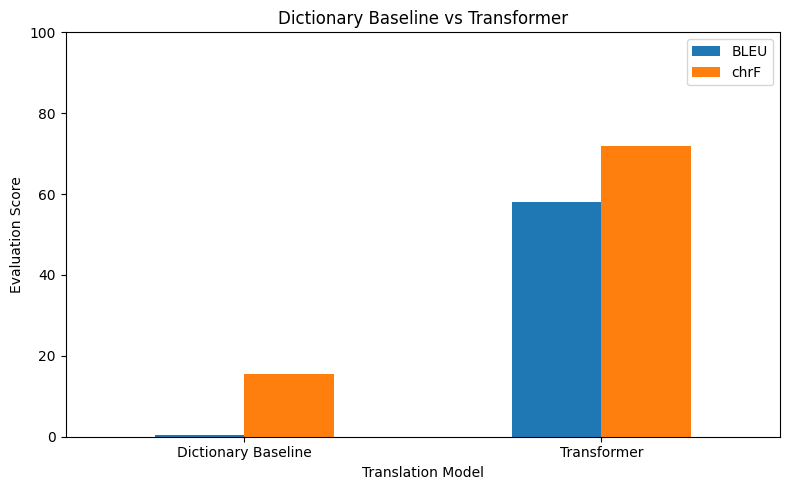

In [18]:

import matplotlib.pyplot as plt

results_df.plot(
    x="Model",
    y=["BLEU", "chrF"],
    kind="bar",
    figsize=(8, 5),
    rot=0
)

plt.title("Dictionary Baseline vs Transformer")
plt.xlabel("Translation Model")
plt.ylabel("Evaluation Score")
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()
